# ¿Por dónde pasa el gas? La red troncal como problema de flujo

El notebook 02 mostró que en el invierno 2026 el gas propio tocó un techo de 141 millones de m³
por día y que el GNL que entró (1.231 millones en 14,5 barcos) fue más de cinco veces el faltante
nacional calculado (221). Este notebook mira el porqué desde la infraestructura: de qué cuenca
sale el gas, por qué caño pasa, con qué capacidad, y a quién no le llega el día más frío cuando
se sacan los barcos.

La red se modela como un grafo: las cinco cuencas y las entradas de importación son los orígenes,
las plantas compresoras son nodos de paso, y las áreas de las distribuidoras y los usuarios directos
son los destinos. Cada arco lleva la capacidad operativa del tramo que publica el ENARGAS en su
informe anual 2025. El flujo máximo desde los orígenes hasta la demanda de un día dice cuánto gas
puede llegar a cada lugar con la red de hoy; la diferencia con lo que se pidió es el faltante por
transporte, y los arcos saturados son el cuello. Después se suman las obras anunciadas, una por una
y combinadas, y se vuelve a correr.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))
from datetime import date
import numpy as np, pandas as pd
from IPython.display import Image, display
from glab import FIGURES, DATA_PROC
from glab import red, figuras
from glab.partes import parse_day
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

## 1. De dónde sale el gas

La serie oficial de producción por cuenca (Secretaría de Energía, Capítulo IV). Toda la suba de los
últimos doce años es de la cuenca Neuquina; las otras cuatro caen. El gas del sur llega por su
propio caño, el San Martín, y el del norte por el Gasoducto Norte: ninguno de los dos sirve para
cubrir el centro del país cuando a Neuquén le falta salida.

In [2]:
cu = pd.read_csv(DATA_PROC / "gas_por_cuenca.csv", parse_dates=["indice_tiempo"]).set_index("indice_tiempo")
dias = cu.index.days_in_month
cols = {"produccion_gas_natural_cuenca_neuquina": "Neuquina", "produccion_gas_natural_cuenca_austral": "Austral",
        "produccion_gas_natural_cuenca_gsj": "Golfo San Jorge", "produccion_gas_natural_cuenca_noroeste": "Noroeste",
        "produccion_gas_natural_cuenca_cuyana": "Cuyana", "produccion_gas_natural_total": "Total"}
diario = cu[list(cols)].div(dias, axis=0).div(1000).rename(columns=cols)   # MMm³/d
inv = diario[diario.index.month.isin([6, 7, 8])].groupby(diario.index[diario.index.month.isin([6, 7, 8])].year).mean()
inv.loc[[2014, 2019, 2024, 2025, 2026]].round(1)

,Neuquina,Austral,Golfo San Jorge,Noroeste,Cuyana,Total
indice_tiempo,,,,,,
2014,64.3,28.2,14.5,7.8,0.2,114.9
2019,90.0,34.7,13.0,5.0,0.1,142.9
2024,112.9,24.0,10.4,3.4,0.1,150.8
2025,117.9,28.5,9.8,3.1,0.1,159.4
2026,121.3,25.0,7.9,2.6,0.1,157.0


## 2. La red de hoy

Los nodos y los arcos del modelo, con la capacidad de cada tramo y su fuente. Donde el invierno 2026
mostró más flujo que la capacidad nominal (la cabecera del Centro Oeste, el Perito Moreno, el tramo
Beazley–La Carlota cuando no se exporta a Chile), se usa lo observado y se dice.

In [3]:
g = red.grafo()
arcos = pd.DataFrame([{"origen": u, "destino": v, "gasoducto": d["gasoducto"], "capacidad": d["cap"], "fuente": d["fuente"]} for u, v, d in g.edges(data=True)])
arcos[arcos.capacidad < 99].sort_values(["gasoducto", "origen"]).reset_index(drop=True)

,origen,destino,gasoducto,capacidad,fuente
0,BUCHANAN,GBA,Anillo GBA,48.9,"Anillo Gran Buenos Aires 48,92"
1,BOLIVIA,NOROESTE,Bolivia,5.6,"obs. 2026 máximo 5,6; sin contrato firme"
2,BEAZLEY,LA_CARLOTA,Centro Oeste,25.0,"obs. 2026: ≥ 25 (tabla ENARGAS 17,5 con export..."
3,LA_CARLOTA,SAN_JERONIMO,Centro Oeste,16.6,"Baldissera–San Jerónimo 16,55"
4,LA_MORA,BEAZLEY,Centro Oeste,27.2,"La Mora–Beazley 27,18"
5,NEUQUINA,PUELEN,Centro Oeste,36.8,"obs. 2026: recibido jun-ago 36,8 (nominal 34,1)"
6,PUELEN,LA_MORA,Centro Oeste,36.8,"obs. 2026: 36,8 en cabecera (tabla ENARGAS 33,..."
7,SAN_JERONIMO,NEA,Centro Oeste,7.9,"San Jerónimo–Aldea Brasilera 7,91 (GNEA)"
8,BAHIA_GNL,CERRI,GNL Bahía Blanca,0.0,sin buque en 2026
9,ESCOBAR,GBA,GNL Escobar,22.0,"buque regasificador; obs. 2026 máximo 21,0"


## 3. El día más frío de 2026, con y sin barcos

El 3 de julio de 2026 el sistema entregó 147 millones de m³ (sin los consumos en boca de pozo):
la demanda de cada distribuidora y de los usuarios directos sale del parte diario. Los directos de
cada transportista se reparten entre nodos con proporciones fijas, porque el parte no dice dónde
están; Camuzzi Sur se parte entre lo que se abastece en la cuenca y lo que va por el San Martín.
La producción por cuenca es la de julio de 2026. Primero con el GNL que entró ese día (20,3 por
Escobar, 1,9 desde Bolivia); después sin nada de eso.

In [4]:
parte = parse_day(date(2026, 7, 3))
PROD = {"neuquina": 122.2, "austral": 25.2, "gsj": 7.9, "noroeste": 2.65}
dem = red.demanda_del_dia(parte, exportacion=1.0)
con = red.flujo_maximo(red.grafo(), red.oferta_del_dia(PROD, parte["gnl_escobar_gasandes"], parte["bolivia_norandino"]), dem)
sin = red.flujo_maximo(red.grafo(), red.oferta_del_dia(PROD, 0.0, 0.0), dem)
t = pd.DataFrame({"demanda": dem, "entregado con GNL": con["entregado"], "faltante con GNL": con["faltante"], "entregado sin GNL": sin["entregado"], "faltante sin GNL": sin["faltante"]})
t.loc["TOTAL"] = t.sum()
salida = sum(d["cap"] for u, v, d in red.grafo().edges(data=True) if u == "NEUQUINA" and v not in ("SUR_CUENCA", "CHILE"))
print(f"Neuquén produce {PROD['neuquina']:.0f} MMm³/d; los caños que salen de la cuenca hacia el resto del país suman {salida:.0f}")
t.round(1)

Neuquén produce 122 MMm³/d; los caños que salen de la cuenca hacia el resto del país suman 99


,demanda,entregado con GNL,faltante con GNL,entregado sin GNL,faltante sin GNL
GBA,54.6,54.6,0.0,39.0,15.6
BAHIA_BLANCA,15.0,15.0,0.0,15.0,0.0
PAMPEANA_INT,15.0,15.0,0.0,14.1,0.9
PATAGONIA,10.1,10.1,0.0,10.1,0.0
SUR_CUENCA,10.3,10.3,0.0,10.3,0.0
MENDOZA,11.9,11.9,0.0,11.9,0.0
CORDOBA,12.4,12.4,0.0,12.4,0.0
SANTA_FE,11.6,11.6,0.0,11.6,0.0
NOA,4.8,4.6,0.3,2.6,2.2
NEA,1.4,0.9,0.6,0.9,0.6


In [5]:
a = sin["arcos"]
a[(a.uso >= 0.95) & (a.capacidad < 99)][["origen", "destino", "gasoducto", "capacidad", "flujo"]].round(1)

,origen,destino,gasoducto,capacidad,flujo
0,NEUQUINA,CERRI,Neuba I + Neuba II,38.1,38.1
3,NEUQUINA,PUELEN,Centro Oeste,36.8,36.8
12,CERRI,OLAVARRIA,Neuba I finales,9.4,9.4
16,ORDOQUI,GBA,Neuba II finales,30.1,30.1
17,OLAVARRIA,GBA,Neuba I finales,8.9,8.9
19,INDIO_RICO,BARKER,San Martín finales,13.6,13.6
20,BARKER,PAMPEANA_INT,San Martín finales,13.6,13.6
25,PUELEN,LA_MORA,Centro Oeste,36.8,36.8
29,BEAZLEY,LA_CARLOTA,Centro Oeste,25.0,24.9


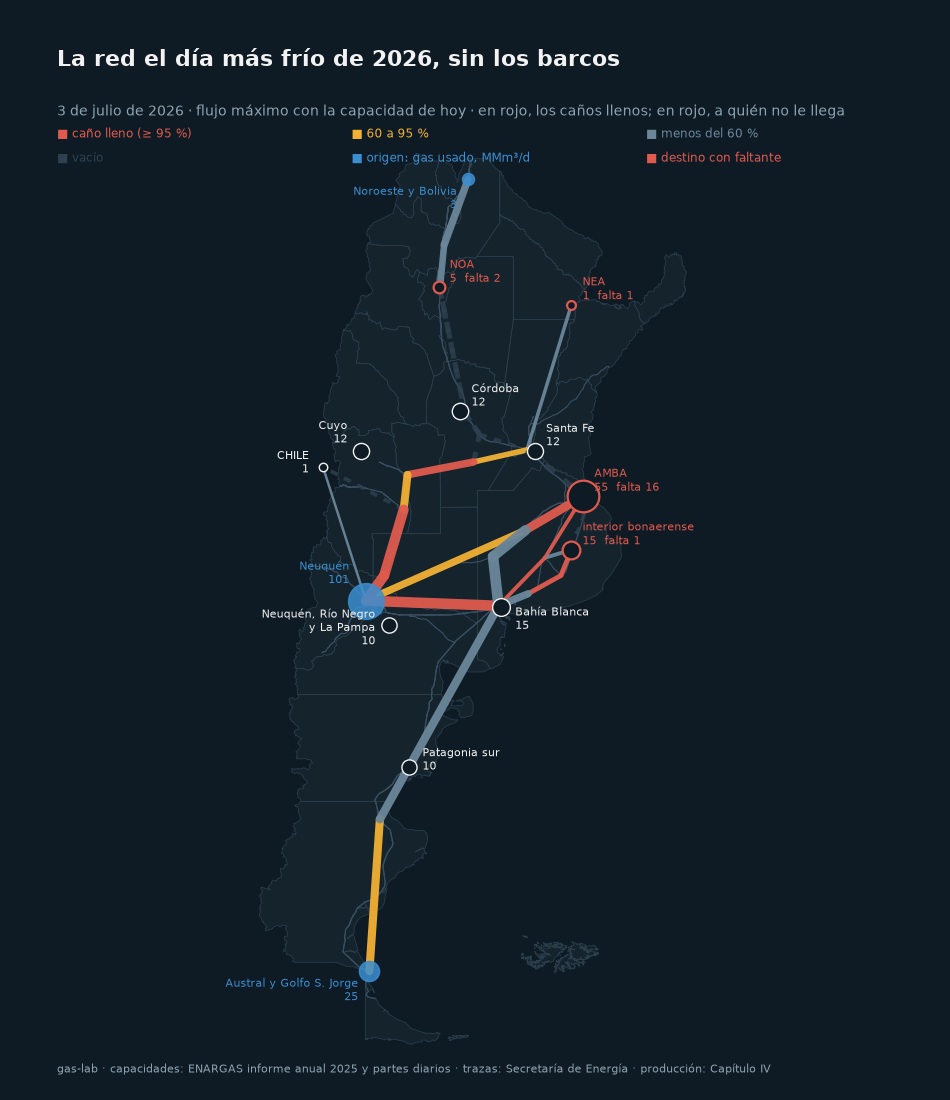

In [6]:
G = np.load(DATA_PROC / "arg_outline.npz"); outline = [G[f"p{i}"] for i in range(int(G["n"]))]; outline = [p for p in outline if p[:, 0].mean() < -52]
L = np.load(DATA_PROC / "red_gasoductos_lineas.npz"); lineas = [L[k] for k in L.files]
figuras.red_mapa(sin, red.NODOS, dem, outline, lineas, FIGURES / "red_hoy.png", "La red el día más frío de 2026, sin los barcos",
                 "3 de julio de 2026 · flujo máximo con la capacidad de hoy · en rojo, los caños llenos; en rojo, a quién no le llega")
figuras.red_mapa(con, red.NODOS, dem, outline, lineas, FIGURES / "red_hoy_gnl.png", "La red el día más frío de 2026, con el GNL de Escobar",
                 "3 de julio de 2026 · 20 millones de m³ entran por Escobar, al lado del AMBA, y el faltante casi desaparece")
display(Image(FIGURES / "red_hoy.png"))

## 4. Qué obra cierra el día más frío sin barcos

Las obras anunciadas, con la capacidad que suman y dónde, una por una y combinadas. Dos días: el
más frío de 2026 tal cual fue, y un día frío de un invierno frío (las distribuidoras un 8 % arriba,
que es la distancia entre el invierno mediano y el p90 del notebook 02, con Neuquén produciendo 135).
Se compara el faltante por transporte sin GNL: lo que habría que cubrir con barcos si la obra fuera
la única.

In [7]:
pd.DataFrame([{"clave": k, "obra": o.nombre, "costo_musd": o.costo_musd, "año": o.anio, "fuente": o.fuente} for k, o in red.OBRAS.items()])

,clave,obra,costo_musd,año,fuente
0,gpm35,Perito Moreno 21 → 35 y su salida a Buenos Aires,780.0,2027.0,"TGS, RIGI Res. 676/2026: 3 compresoras en La P..."
1,norte19,"Compresoras del Norte, 15 → 19",NaN,NaN,"Enarsa: Lavalle, Lumbreras, Deán Funes y Ferre..."
2,tlc,"Tratayén–La Carlota, 13",1500.0,2029.0,TGN 17/9/2026
3,tgn14,"Loops y compresión TGN, +14",700.0,2029.0,TGN: 147 km de loops y 71.000 HP; el reparto e...
4,gnk2,"Kirchner etapa 2, Salliqueló–San Jerónimo",NaN,NaN,capa 'ductos proyectados' de la Secretaría de ...
5,escobar2,Segundo buque regasificador,NaN,NaN,alternativa sin caños


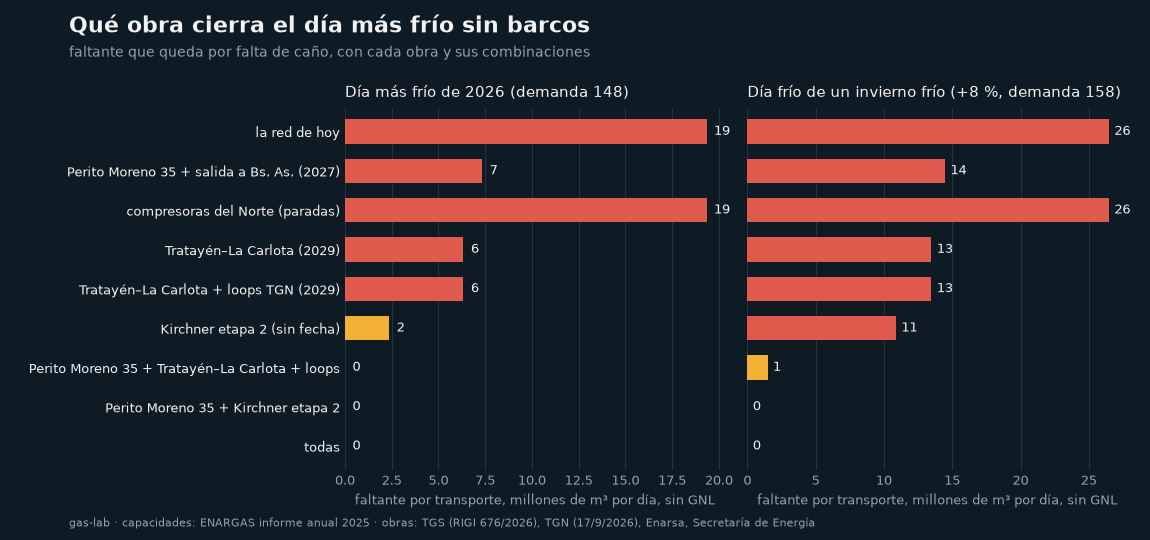

,Día más frío de 2026 (demanda 148),"Día frío de un invierno frío (+8 %, demanda 158)"
la red de hoy,19.3,26.5
Perito Moreno 35 + salida a Bs. As. (2027),7.3,14.5
compresoras del Norte (paradas),19.3,26.5
Tratayén–La Carlota (2029),6.3,13.5
Tratayén–La Carlota + loops TGN (2029),6.3,13.5
Kirchner etapa 2 (sin fecha),2.4,10.9
Perito Moreno 35 + Tratayén–La Carlota + loops,0.0,1.5
Perito Moreno 35 + Kirchner etapa 2,0.0,0.0
todas,0.0,0.0


In [8]:
combos = {"hoy": [], "gpm35": ["gpm35"], "norte19": ["norte19"], "tlc": ["tlc"], "tlc+tgn14": ["tlc", "tgn14"], "gnk2": ["gnk2"],
          "gpm35+tlc+tgn14": ["gpm35", "tlc", "tgn14"], "gpm35+gnk2": ["gpm35", "gnk2"], "todo": ["gpm35", "norte19", "tlc", "tgn14", "gnk2"]}
rot = {"hoy": "la red de hoy", "gpm35": "Perito Moreno 35 + salida a Bs. As. (2027)", "norte19": "compresoras del Norte (paradas)",
       "tlc": "Tratayén–La Carlota (2029)", "tlc+tgn14": "Tratayén–La Carlota + loops TGN (2029)", "gnk2": "Kirchner etapa 2 (sin fecha)",
       "gpm35+tlc+tgn14": "Perito Moreno 35 + Tratayén–La Carlota + loops", "gpm35+gnk2": "Perito Moreno 35 + Kirchner etapa 2", "todo": "todas"}
tablas = {}
for titulo, escala, prodn in [("Día más frío de 2026 (demanda 148)", 1.0, 122.2), ("Día frío de un invierno frío (+8 %, demanda 158)", 1.08, 135.0)]:
    d = red.demanda_del_dia(parte, exportacion=1.0, escala_distribuidoras=escala)
    tablas[titulo] = red.comparar_obras(red.oferta_del_dia({**PROD, "neuquina": prodn}, 0.0, 0.0), d, combos)
    tablas[titulo].round(2).to_csv(DATA_PROC / f"red_obras_{'frio' if escala > 1 else '2026'}.csv")
figuras.red_obras(tablas, FIGURES / "red_obras.png", list(combos), rot)
resumen = pd.DataFrame({k: v["faltante_total"] for k, v in tablas.items()}).rename(index=rot)
display(Image(FIGURES / "red_obras.png"))
resumen.round(1)

In [9]:
tablas["Día frío de un invierno frío (+8 %, demanda 158)"].rename(index=rot)[["faltante_total", "GBA", "SANTA_FE", "CORDOBA", "NOA", "NEA", "PAMPEANA_INT"]].round(1)

,faltante_total,GBA,SANTA_FE,CORDOBA,NOA,NEA,PAMPEANA_INT
la red de hoy,26.5,18.9,1.4,0.0,2.6,1.6,2.0
Perito Moreno 35 + salida a Bs. As. (2027),14.5,6.9,1.4,0.0,2.6,1.6,2.0
compresoras del Norte (paradas),26.5,18.9,1.4,0.0,2.6,1.6,2.0
Tratayén–La Carlota (2029),13.5,8.9,0.0,0.0,2.6,0.0,2.0
Tratayén–La Carlota + loops TGN (2029),13.5,8.9,0.0,0.0,2.6,0.0,2.0
Kirchner etapa 2 (sin fecha),10.9,0.9,0.0,0.0,2.6,0.0,7.4
Perito Moreno 35 + Tratayén–La Carlota + loops,1.5,0.0,0.0,0.0,1.5,0.0,0.0
Perito Moreno 35 + Kirchner etapa 2,0.0,0.0,0.0,0.0,0.0,0.0,0.0
todas,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 5. El invierno entero: cuánto GNL evita cada obra y en cuántos inviernos se paga

El día más frío dice dónde está el cuello; el invierno entero dice cuánto cuesta. Para cada uno de
los 153 días de mayo a septiembre de 2026 se corre el flujo máximo sin barcos, con la demanda del
parte de ese día y la producción por cuenca de ese mes. El faltante del día es el GNL mínimo que
ese día necesita (el del NOA no: al NOA el GNL de Escobar no llega, lo cubre Bolivia o la
reversión del Norte, y se informa aparte). La suma del invierno, con cada obra, es el GNL que la
obra evita. A 0,65 millones de dólares por millón de m³ puesto en Escobar (2025 fue 0,54 con 27
cargamentos y US$ 698 millones), eso da el ahorro por invierno y los inviernos que la obra tarda en
pagarse. Los costos son los publicados por TGS y TGN; el de la etapa 2 del Kirchner se estima a
2 millones de dólares por kilómetro, lo que cuesta el Tratayén–La Carlota.

In [10]:
import json
from datetime import timedelta
cache = DATA_PROC / "partes_invierno_2026.json"
if cache.exists():
    partes = json.loads(cache.read_text(encoding="utf-8"))
else:
    partes, d = [], date(2026, 5, 1)
    while d <= date(2026, 9, 30):
        try:
            p = parse_day(d); p["fecha"] = str(p["fecha"]); partes.append(p)
        except Exception:
            pass
        d += timedelta(days=1)
    cache.write_text(json.dumps(partes, default=str), encoding="utf-8")
prod_mes = red.produccion_mensual(DATA_PROC / "gas_por_cuenca.csv")
hoy_inv = red.faltante_invierno(partes, prod_mes, [])
print(f"{len(partes)} días · GNL mínimo por transporte con la red de hoy: {hoy_inv['faltante'].sum() - hoy_inv['falta_NOA'].sum():.0f} MMm³ en {(hoy_inv['faltante'] > 0.05).sum()} días; "
      f"GNL real del invierno: {hoy_inv['gnl_real'].sum():.0f} · correlación diaria {hoy_inv['faltante'].corr(hoy_inv['gnl_real']):.2f}")
hoy_inv.filter(like="falta_").sum().round(0).rename(lambda s: s[6:]).to_frame("MMm³ del invierno").T

153 días · GNL mínimo por transporte con la red de hoy: 498 MMm³ en 83 días; GNL real del invierno: 1231 · correlación diaria 0.82


,GBA,BAHIA_BLANCA,PAMPEANA_INT,PATAGONIA,SUR_CUENCA,MENDOZA,CORDOBA,SANTA_FE,NOA,NEA,CHILE
MMm³ del invierno,489.0,0.0,7.0,0.0,0.0,0.0,0.0,0.0,96.0,3.0,0.0


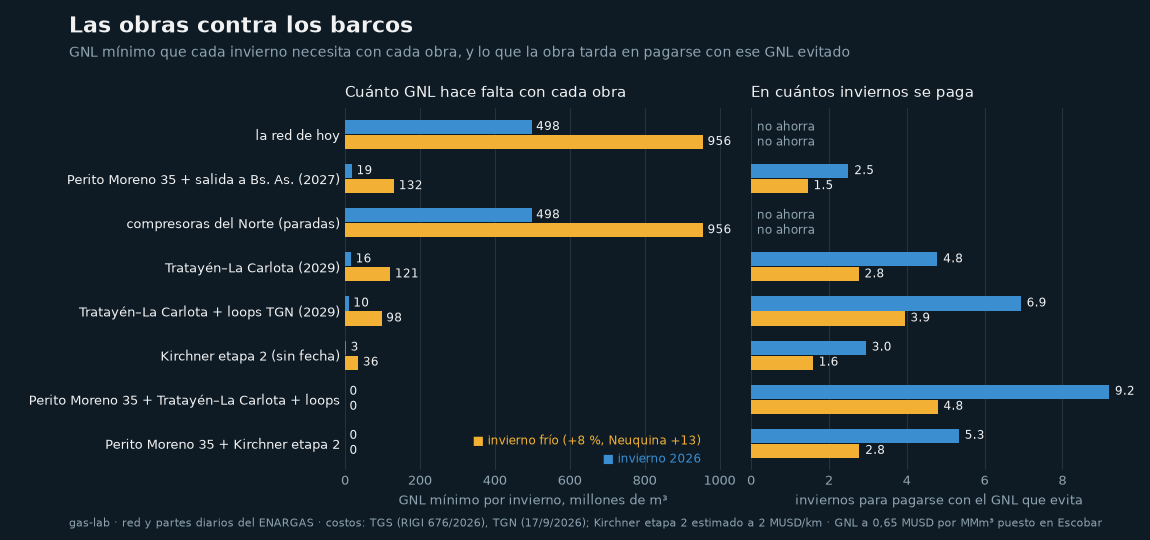

,gnl_minimo_mmm3,norte_minimo_mmm3,dias_con_faltante,faltante_max_dia,ahorro_mmm3,ahorro_musd_por_invierno,costo_musd,inviernos_para_pagarse
la red de hoy,498.3,96.4,83.0,19.3,0.0,0.0,NaN,NaN
Perito Moreno 35 + salida a Bs. As. (2027),18.8,21.8,21.0,7.3,479.6,311.7,780.0,2.5
compresoras del Norte (paradas),498.3,96.4,83.0,19.3,0.0,0.0,NaN,NaN
Tratayén–La Carlota (2029),16.4,7.2,12.0,6.3,482.0,313.3,1500.0,4.8
Tratayén–La Carlota + loops TGN (2029),10.1,10.5,9.0,6.3,488.3,317.4,2200.0,6.9
Kirchner etapa 2 (sin fecha),3.1,0.3,2.0,2.3,495.2,321.9,950.0,3.0
Perito Moreno 35 + Tratayén–La Carlota + loops,0.0,0.0,0.0,0.0,498.3,323.9,2980.0,9.2
Perito Moreno 35 + Kirchner etapa 2,0.0,0.0,0.0,0.0,498.3,323.9,1730.0,5.3


In [11]:
combos_b = {k: v for k, v in combos.items() if k != "todo"}
costos = {"gpm35": 780, "tlc": 1500, "tlc+tgn14": 2200, "gnk2": 950, "gpm35+tlc+tgn14": 2980, "gpm35+gnk2": 1730}
balances = {}
for titulo, escala, extra in [("invierno 2026", 1.0, 0.0), ("invierno frío (+8 %, Neuquina +13)", 1.08, 13.0)]:
    balances[titulo] = red.balance_obras(partes, prod_mes, combos_b, costos, escala_distribuidoras=escala, neuquina_extra=extra)
    balances[titulo].round(2).to_csv(DATA_PROC / f"red_balance_{'frio' if escala > 1 else '2026'}.csv")
figuras.red_balance(balances, FIGURES / "red_balance.png", list(combos_b), rot)
display(Image(FIGURES / "red_balance.png"))
balances["invierno 2026"].rename(index=rot).round(1)

In [12]:
balances["invierno frío (+8 %, Neuquina +13)"].rename(index=rot).round(1)

,gnl_minimo_mmm3,norte_minimo_mmm3,dias_con_faltante,faltante_max_dia,ahorro_mmm3,ahorro_musd_por_invierno,costo_musd,inviernos_para_pagarse
la red de hoy,956.1,150.6,109.0,26.5,0.0,0.0,NaN,NaN
Perito Moreno 35 + salida a Bs. As. (2027),131.7,65.8,46.0,14.5,824.4,535.9,780.0,1.5
compresoras del Norte (paradas),956.1,150.6,109.0,26.5,0.0,0.0,NaN,NaN
Tratayén–La Carlota (2029),121.4,38.0,36.0,13.5,834.7,542.6,1500.0,2.8
Tratayén–La Carlota + loops TGN (2029),98.2,58.0,35.0,13.5,857.9,557.6,2200.0,3.9
Kirchner etapa 2 (sin fecha),35.6,8.3,16.0,10.8,920.5,598.3,950.0,1.6
Perito Moreno 35 + Tratayén–La Carlota + loops,0.0,2.2,2.0,1.5,956.1,621.5,2980.0,4.8
Perito Moreno 35 + Kirchner etapa 2,0.0,0.0,0.0,0.0,956.1,621.5,1730.0,2.8


## Lo que el modelo no mide

- **Es un flujo máximo, no una simulación hidráulica.** No hay presiones, line pack ni combustible
  de compresoras (2 a 4 % del gas transportado). Las capacidades son las que publica el ENARGAS
  por tramo, que son flujos de diseño: donde el invierno 2026 mostró más, se usa lo observado.
- **Un nodo por distribuidora.** Dentro de cada área el gas se reparte sin límite; los cortes a
  industrias dentro de una misma área no se ven. Los usuarios directos de cada transportista se
  reparten entre nodos con proporciones fijas, declaradas en `red.REPARTO_DIRECTOS`.
- **La demanda es la entregada, no la pedida.** El parte diario registra lo que se entregó después
  de los cortes a industrias, GNC y centrales. El faltante real de un día frío es mayor que el que
  se calcula acá.
- **Las obras se modelan como capacidad que se suma a un arco.** El reparto de los 14 millones de
  loops y compresión de TGN entre tramos es un supuesto; el costo y la fecha de la etapa 2 del
  Kirchner no están publicados.
- **No dice qué conviene hacer.** Dice qué obra cierra cuánto faltante y dónde. El costo por unidad
  de capacidad y su comparación con los barcos es el paso siguiente.